# 01 – Eksploracyjna analiza danych (EDA)

Podzbiór CIC-Darknet2020 po `src/preprocess.py` (wariant A): usługi WWW, VoIP, Video, ruch zwykły (Non-Tor + NonVPN) i VPN.
Dane: `data/processed/flows.parquet` (Release `data-processed-v1`).

Pytania tego notatnika:
1. Ile mamy przepływów i sesji w każdej kombinacji?
2. Czym różnią się usługi w kluczowych cechach i które grupy cech niosą najwięcej informacji (wstęp do P1)?
3. Które cechy są nadmiarowe (silnie skorelowane)?
4. **Jak silny jest efekt kampanii pomiarowej?** WWW pochodzi z innej kampanii niż VoIP; wideo jest w obu, więc pozwala to zmierzyć.
5. Jak VPN zmienia rozkłady cech VoIP i wideo (wstęp do P3)?

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score

from features import SERVICES, feature_groups, feature_group, feature_list, load_flows

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
PALETTE = {"WWW": "#4C72B0", "VoIP": "#DD8452", "Video": "#55A868"}
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

df = load_flows()
FEATURES = feature_list()
GROUPS = feature_groups(FEATURES)
plain = df[df["tunnel"] == "plain"]
print(f"{len(df):,} przepływów, {len(FEATURES)} cech")
{g: len(f) for g, f in GROUPS.items()}

26,515 przepływów, 62 cech


{'tcp_protokol': 10,
 'czasowe': 19,
 'licznosci': 6,
 'rozmiarowe': 22,
 'tempo': 5}

## 1. Liczności przepływów i sesji

In [2]:
counts = df.groupby(["tunnel", "traffic_type", "service"]).agg(
    przeplywy=("session", "size"), sesje=("session", "nunique"))
counts["przeplywy_na_sesje"] = (counts["przeplywy"] / counts["sesje"]).round(1)
counts

przeplywy  sesje  przeplywy_na_sesje
tunnel traffic_type service                                      
plain  Non-Tor      Video         2364    369                 6.4
                    WWW          20033   3285                 6.1
       NonVPN       Video         2712    462                 5.9
                    VoIP           204     49                 4.2
vpn    VPN          Video         1015    138                 7.4
                    VoIP           187     25                 7.5

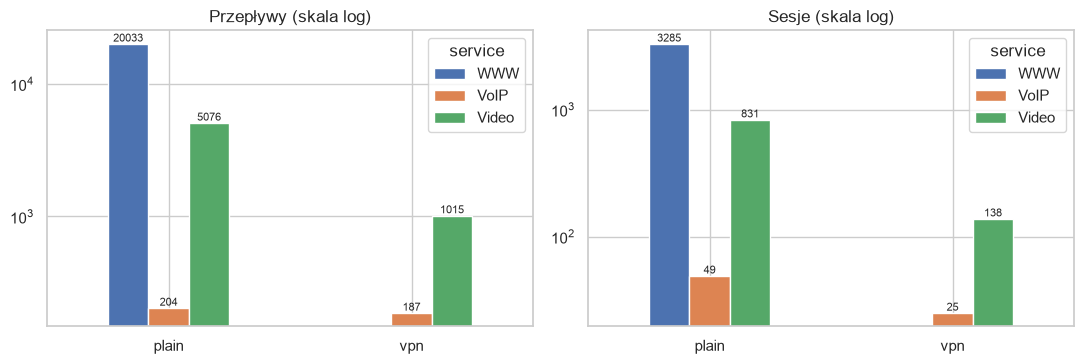

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in zip(axes, ["przeplywy", "sesje"], ["Przepływy", "Sesje"]):
    t = counts[col].groupby(["tunnel", "service"]).sum().unstack("service").reindex(columns=SERVICES)
    t.plot.bar(ax=ax, color=[PALETTE[s] for s in SERVICES], rot=0)
    ax.set_yscale("log"); ax.set_title(f"{title} (skala log)"); ax.set_xlabel("")
    for c in ax.containers:
        ax.bar_label(c, fmt="%d", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "01_licznosci.png", dpi=150)

## 2. Wielkość sesji

Przy podziale grupowym duże sesje ważą najwięcej: jedna sesja z 30% przepływów klasy przesądza o wyniku foldu.

count  mean   std  min  50%   90%   99%    max
service tunnel                                                 
Video   plain    831.0   6.1   9.1  1.0  3.0  12.0  43.7   98.0
        vpn      138.0   7.4  13.5  1.0  4.0  14.0  63.5  128.0
VoIP    plain     49.0   4.2   9.4  1.0  2.0   7.2  43.8   62.0
        vpn       25.0   7.5   9.0  1.0  2.0  21.0  30.8   31.0
WWW     plain   3285.0   6.1   9.5  1.0  4.0  12.0  41.2  227.0

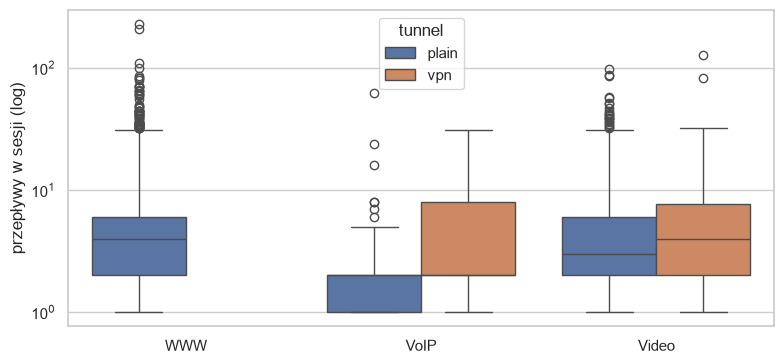

In [4]:
sess = df.groupby(["service", "tunnel", "session"]).size().rename("n").reset_index()
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=sess, x="service", y="n", hue="tunnel", order=SERVICES, ax=ax, log_scale=True)
ax.set_ylabel("przepływy w sesji (log)"); ax.set_xlabel("")
fig.tight_layout(); fig.savefig(FIG / "02_wielkosc_sesji.png", dpi=150)
sess.groupby(["service", "tunnel"])["n"].describe(percentiles=[.5, .9, .99]).round(1)

## 3. Rozkłady kluczowych cech – ruch zwykły

Cechy mają rozkłady o długich ogonach, więc pokazuję log10(1 + x). Czasy w CICFlowMeter są w mikrosekundach.

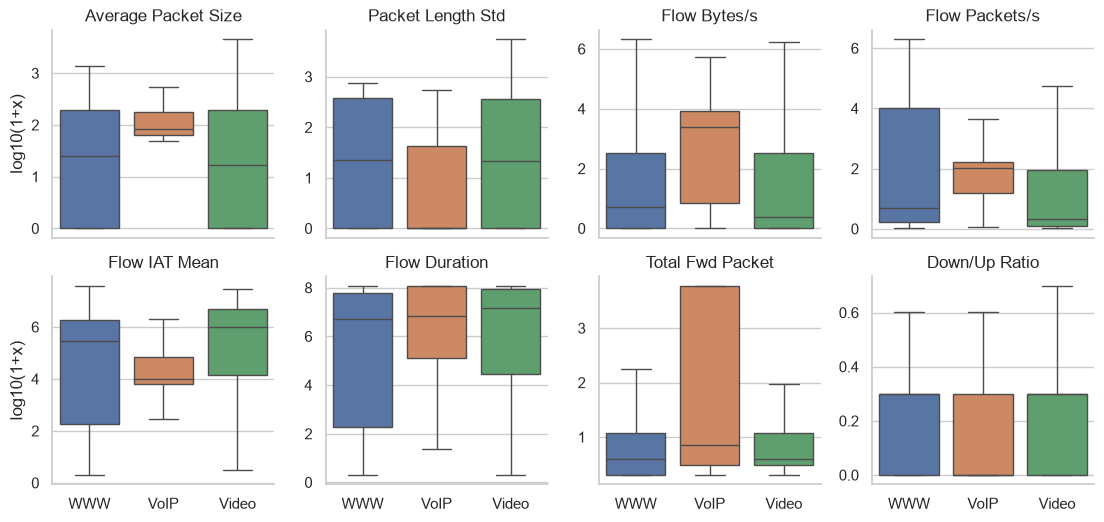

In [5]:
KEY = ["Average Packet Size", "Packet Length Std", "Flow Bytes/s", "Flow Packets/s",
       "Flow IAT Mean", "Flow Duration", "Total Fwd Packet", "Down/Up Ratio"]
long = plain.melt(id_vars="service", value_vars=KEY, var_name="cecha", value_name="v")
long["log10(1+x)"] = np.log10(1 + long["v"].clip(lower=0))
g = sns.catplot(data=long, x="service", y="log10(1+x)", col="cecha", col_wrap=4, kind="box",
                order=SERVICES, palette=PALETTE, hue="service", sharey=False, height=2.8, showfliers=False)
g.set_titles("{col_name}"); g.set_xlabels("")
g.figure.savefig(FIG / "03_kluczowe_cechy.png", dpi=150)

In [6]:
summary = plain.groupby("service")[KEY].median().T.reindex(columns=SERVICES)
summary["udział UDP"] = np.nan
udp = plain.groupby("service")["Protocol"].apply(lambda s: (s == 17).mean())
print("Udział UDP:", udp.reindex(SERVICES).round(2).to_dict())
summary.drop(columns="udział UDP").round(1)

Udział UDP: {'WWW': 0.0, 'VoIP': 0.62, 'Video': 0.04}


service,WWW,VoIP,Video
Average Packet Size,24.4,83.0,15.8
Packet Length Std,21.3,0.0,20.7
Flow Bytes/s,4.3,2491.0,1.5
Flow Packets/s,3.8,100.0,1.1
Flow IAT Mean,282650.8,10000.2,1001878.0
Flow Duration,4994644.0,6990737.0,14231661.0
Total Fwd Packet,3.0,6.0,3.0
Down/Up Ratio,1.0,0.0,1.0


## 4. Informacyjność pojedynczych cech (wstęp do P1)

Informacja wzajemna (mutual information) każdej cechy z usługą, osobno dla ruchu zwykłego.
To miara jednowymiarowa: nie widzi interakcji cech, więc jest tylko wstępem do E4.

,count,mean,max
grupa,,,
czasowe,19,0.251,0.511
tcp_protokol,10,0.119,0.326
rozmiarowe,22,0.140,0.288
tempo,5,0.163,0.224
licznosci,6,0.044,0.074


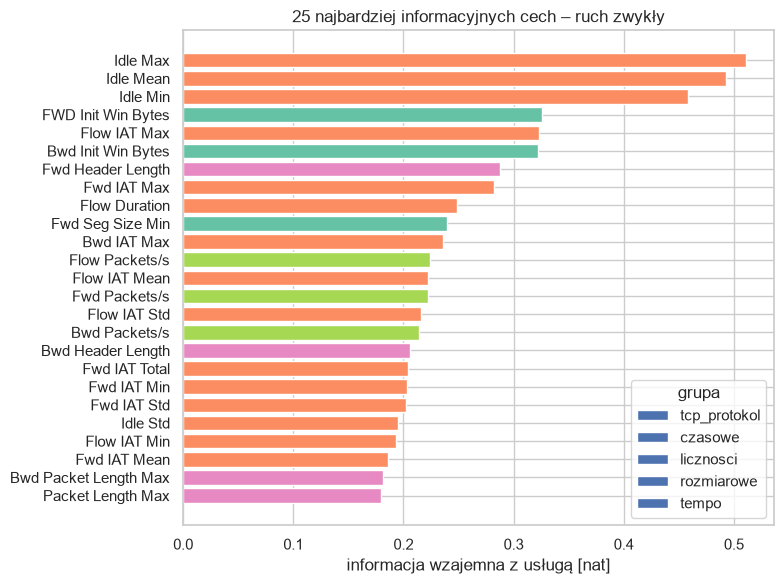

In [7]:
sample = pd.concat([g.sample(min(len(g), 5000), random_state=SEED)
                    for _, g in plain.groupby("service")])
mi = pd.Series(mutual_info_classif(sample[FEATURES], sample["service"], random_state=SEED),
               index=FEATURES, name="MI").sort_values(ascending=False)
mi_df = mi.to_frame().assign(grupa=[feature_group(f) for f in mi.index])

fig, ax = plt.subplots(figsize=(8, 6))
top = mi_df.head(25).iloc[::-1]
gcol = dict(zip(GROUPS, sns.color_palette("Set2", len(GROUPS))))
ax.barh(top.index, top["MI"], color=[gcol[g] for g in top["grupa"]])
for g, c in gcol.items():
    ax.barh([], [], color=c, label=g)
ax.legend(title="grupa", loc="lower right"); ax.set_xlabel("informacja wzajemna z usługą [nat]")
ax.set_title("25 najbardziej informacyjnych cech – ruch zwykły")
fig.tight_layout(); fig.savefig(FIG / "04_informacja_wzajemna.png", dpi=150)

mi_df.groupby("grupa")["MI"].agg(["count", "mean", "max"]).sort_values("max", ascending=False).round(3)

## 5. Korelacje i nadmiarowość cech

Wiele cech CICFlowMeter to warianty tej samej wielkości (np. `Packet Length Std` i `Variance`, `Subflow Fwd Bytes` i `Total Length of Fwd Packet`).
Dla drzew to nie problem, ale k-NN liczy odległość, więc nadmiarowe cechy zwielokrotniają wagę jednej informacji.

In [8]:
corr = plain[FEATURES].corr(method="spearman").fillna(0)
cg = sns.clustermap(corr, cmap="vlag", center=0, figsize=(13, 13), xticklabels=True, yticklabels=True,
                    cbar_pos=(0.02, 0.85, 0.02, 0.1))
cg.ax_heatmap.tick_params(labelsize=6)
cg.figure.savefig(FIG / "05_korelacje.png", dpi=150)
plt.close(cg.figure)

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high = upper[upper.abs() >= 0.98].sort_values(ascending=False)
print(f"Pary cech o |rho Spearmana| >= 0.98: {len(high)}")
high.head(20).round(3)

Pary cech o |rho Spearmana| >= 0.98: 30


Bwd Packet Length Mean      Bwd Segment Size Avg      1.000
Fwd Packet Length Mean      Fwd Segment Size Avg      1.000
Packet Length Std           Packet Length Variance    1.000
Protocol                    Packet Length Min         1.000
Packet Length Mean          Average Packet Size       1.000
Bwd Packet Length Mean      Subflow Bwd Bytes         0.999
Bwd Segment Size Avg        Subflow Bwd Bytes         0.999
Fwd Packet Length Mean      Subflow Fwd Bytes         0.996
Fwd Segment Size Avg        Subflow Fwd Bytes         0.996
Flow Packets/s              Fwd Packets/s             0.994
Total Length of Bwd Packet  Subflow Bwd Bytes         0.991
                            Bwd Segment Size Avg      0.990
                            Bwd Packet Length Mean    0.990
Packet Length Mean          Packet Length Std         0.990
                            Packet Length Variance    0.990
Packet Length Variance      Average Packet Size       0.989
Packet Length Std           Average Pack

## 6. Efekt kampanii pomiarowej

WWW występuje tylko w kampanii Tor-nonTor, VoIP tylko w VPN-nonVPN. Wideo jest w obu, więc porównanie
**wideo z kampanii Tor-nonTor vs wideo z kampanii VPN-nonVPN** pokazuje, ile różnicy wnosi sama kampania przy tej samej usłudze.

Dla każdej cechy liczę statystykę Kołmogorowa–Smirnowa (0 = identyczne rozkłady, 1 = rozłączne):
- **efekt kampanii:** wideo Non-Tor vs wideo NonVPN,
- **efekt usługi:** WWW vs wideo w tej samej kampanii (Non-Tor).

Cechy, w których efekt kampanii dorównuje efektowi usługi, są podejrzane jako „skróty”.

,kampania (wideo),usługa (WWW vs wideo),grupa
Fwd Seg Size Min,0.86,0.02,tcp_protokol
Bwd Init Win Bytes,0.69,0.18,tcp_protokol
Idle Max,0.68,0.61,czasowe
Idle Mean,0.59,0.41,czasowe
FWD Init Win Bytes,0.59,0.17,tcp_protokol
Idle Min,0.58,0.40,czasowe
Flow IAT Min,0.33,0.29,czasowe
Bwd Packet Length Std,0.31,0.11,rozmiarowe
Bwd Packet Length Max,0.30,0.11,rozmiarowe
Packet Length Max,0.28,0.14,rozmiarowe


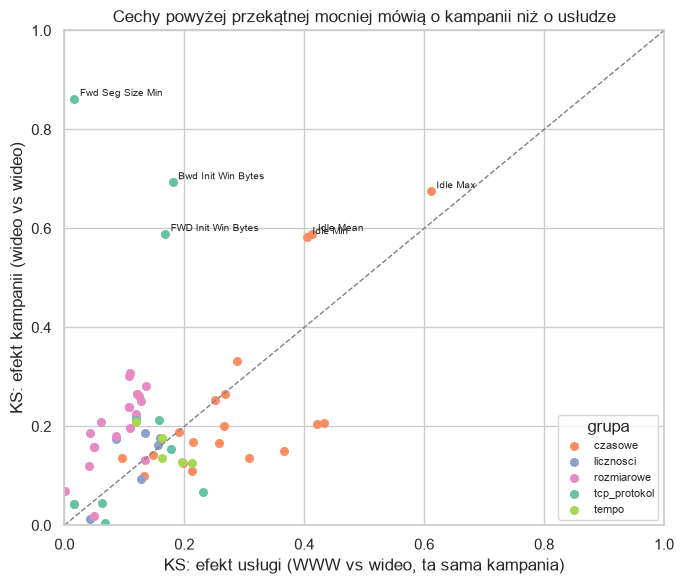

In [9]:
vid = plain[plain["service"] == "Video"]
v_tor = vid[vid["campaign"] == "tor-nontor"]
v_vpn = vid[vid["campaign"] == "vpn-nonvpn"]
www = plain[plain["service"] == "WWW"]

ks = pd.DataFrame({
    "kampania (wideo)": [ks_2samp(v_tor[f], v_vpn[f]).statistic for f in FEATURES],
    "usługa (WWW vs wideo)": [ks_2samp(www[f], v_tor[f]).statistic for f in FEATURES],
}, index=FEATURES)
ks["grupa"] = [feature_group(f) for f in FEATURES]

fig, ax = plt.subplots(figsize=(7, 6))
for g, sub in ks.groupby("grupa"):
    ax.scatter(sub["usługa (WWW vs wideo)"], sub["kampania (wideo)"], label=g, color=gcol[g], s=30)
ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
for f, r in ks.nlargest(6, "kampania (wideo)").iterrows():
    ax.annotate(f, (r["usługa (WWW vs wideo)"], r["kampania (wideo)"]), fontsize=7,
                xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("KS: efekt usługi (WWW vs wideo, ta sama kampania)")
ax.set_ylabel("KS: efekt kampanii (wideo vs wideo)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(title="grupa", fontsize=8)
ax.set_title("Cechy powyżej przekątnej mocniej mówią o kampanii niż o usłudze")
fig.tight_layout(); fig.savefig(FIG / "06_efekt_kampanii.png", dpi=150)

ks.sort_values("kampania (wideo)", ascending=False).head(12).round(2)

Początkowe okno TCP zależy od systemu operacyjnego i konfiguracji hosta. Najczęstsze wartości w każdej kombinacji:

In [10]:
def top_values(s, k=3):
    vc = s.value_counts(normalize=True).head(k)
    return ", ".join(f"{int(v)} ({p:.0%})" for v, p in vc.items())

tcp = df[df["Protocol"] == 6]
tcp.groupby(["campaign", "tunnel", "service"]).agg(
    fwd_init_win=("FWD Init Win Bytes", top_values),
    bwd_init_win=("Bwd Init Win Bytes", top_values))

fwd_init_win                      bwd_init_win
campaign   tunnel service                                                                        
tor-nontor plain  Video      14600 (34%), 2640 (18%), 1047 (4%)    0 (17%), 2640 (13%), 1047 (9%)
                  WWW          14600 (51%), 2640 (6%), 980 (6%)    980 (16%), 0 (12%), 14600 (9%)
vpn-nonvpn plain  Video          29200 (18%), 1444 (7%), 0 (5%)       0 (21%), 358 (4%), 366 (4%)
                  VoIP     8192 (25%), 65535 (22%), 32768 (10%)  0 (39%), 32768 (10%), 16456 (9%)
           vpn    Video       29200 (19%), 1444 (13%), 237 (8%)      350 (12%), 0 (11%), 358 (7%)
                  VoIP     65535 (28%), 8192 (25%), 32768 (17%)     0 (47%), 32768 (17%), 31 (4%)

### Wstępny test: czy model odróżnia kampanię przy tej samej usłudze?

Random Forest uczy się przewidywać **kampanię** na samych przepływach wideo (podział grupowy po sesjach, 5 foldów, zbalansowana dokładność).
0,5 = kampanii nie da się odróżnić, 1,0 = kampania jest w pełni rozpoznawalna. To zapowiedź testu kontrolnego z M4, nie jego ostateczna wersja.

In [11]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED, class_weight="balanced")
variants = {
    "wszystkie cechy": FEATURES,
    "bez TCP/protokołu": [f for f in FEATURES if feature_group(f) != "tcp_protokol"],
    "tylko czasowe": GROUPS["czasowe"],
    "tylko rozmiarowe": GROUPS["rozmiarowe"],
}
camp = {}
for name, cols in variants.items():
    s = cross_val_score(rf, vid[cols], vid["campaign"], groups=vid["session"], cv=cv,
                        scoring="balanced_accuracy")
    camp[name] = (s.mean(), s.std())
pd.DataFrame(camp, index=["zbalansowana dokładność", "odch. std"]).T.round(3)

,zbalansowana dokładność,odch. std
wszystkie cechy,0.997,0.002
bez TCP/protokołu,0.989,0.006
tylko czasowe,0.924,0.016
tylko rozmiarowe,0.961,0.017


## 7. Ruch zwykły vs VPN (VoIP i wideo, kampania VPN-nonVPN)

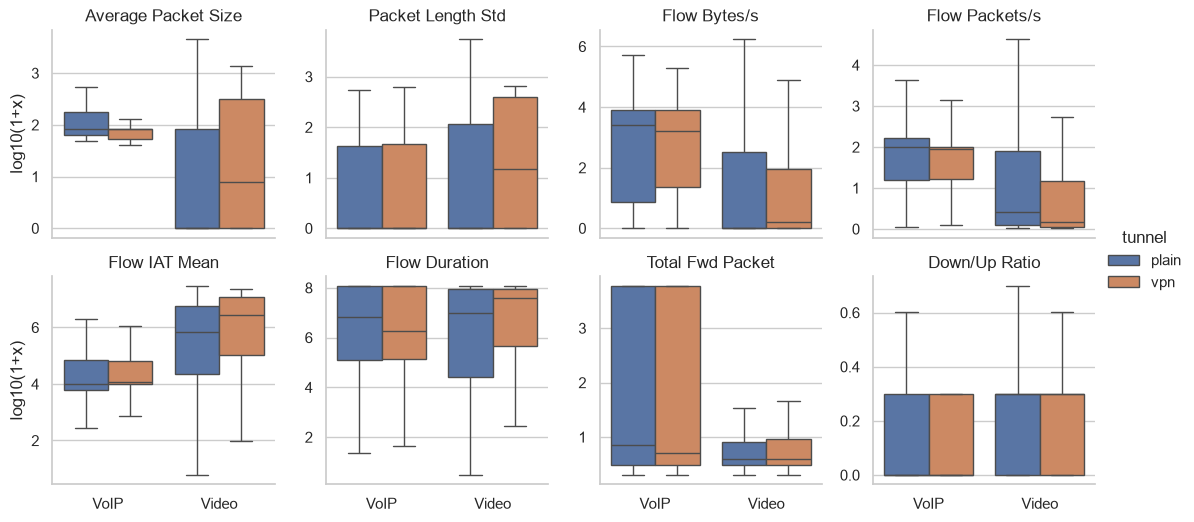

In [12]:
vv = df[(df["campaign"] == "vpn-nonvpn") & df["service"].isin(["VoIP", "Video"])]
long = vv.melt(id_vars=["service", "tunnel"], value_vars=KEY, var_name="cecha", value_name="v")
long["log10(1+x)"] = np.log10(1 + long["v"].clip(lower=0))
g = sns.catplot(data=long, x="service", y="log10(1+x)", hue="tunnel", col="cecha", col_wrap=4,
                kind="box", sharey=False, height=2.8, showfliers=False, order=["VoIP", "Video"])
g.set_titles("{col_name}"); g.set_xlabels("")
g.figure.savefig(FIG / "07_vpn_vs_zwykly.png", dpi=150)

In [13]:
ks_vpn = pd.DataFrame({
    s: [ks_2samp(vv.loc[(vv.service == s) & (vv.tunnel == "plain"), f],
                 vv.loc[(vv.service == s) & (vv.tunnel == "vpn"), f]).statistic for f in FEATURES]
    for s in ["VoIP", "Video"]}, index=FEATURES)
ks_vpn["VoIP vs Video (zwykły)"] = [
    ks_2samp(vv.loc[(vv.service == "VoIP") & (vv.tunnel == "plain"), f],
             vv.loc[(vv.service == "Video") & (vv.tunnel == "plain"), f]).statistic for f in FEATURES]
ks_vpn["grupa"] = [feature_group(f) for f in FEATURES]
print("Średni KS w grupach: zmiana od VPN (VoIP, Video) vs różnica między usługami")
ks_vpn.groupby("grupa").mean(numeric_only=True).round(2)

Średni KS w grupach: zmiana od VPN (VoIP, Video) vs różnica między usługami


,VoIP,Video,VoIP vs Video (zwykły)
grupa,,,
czasowe,0.29,0.28,0.40
licznosci,0.15,0.07,0.29
rozmiarowe,0.15,0.11,0.42
tcp_protokol,0.04,0.06,0.37
tempo,0.28,0.13,0.41


## 8. Wnioski

1. **Efekt kampanii jest bardzo silny.** Random Forest odróżnia wideo z kampanii Tor-nonTor od wideo z kampanii VPN-nonVPN z dokładnością zbalansowaną **0,997**. Bez cech TCP/protokołu nadal 0,989, na samych cechach czasowych 0,92, na samych rozmiarowych 0,96. Różnice środowiska pomiarowego przenikają więc do prawie wszystkich grup cech. Klasyfikator trzech usług, w którym WWW pochodzi z innej kampanii niż VoIP, może osiągać wysoki wynik, rozpoznając kampanię, a nie usługę.
2. **Najsilniejsze skróty to cechy TCP zależne od systemu operacyjnego:** `Fwd Seg Size Min` (KS 0,86 dla kampanii i 0,02 dla usługi; to rozmiar nagłówka TCP, który zależy od opcji takich jak znaczniki czasu), `Bwd/FWD Init Win Bytes` (początkowe okno TCP) oraz cechy `Idle *`.
3. **Wewnątrz jednej kampanii WWW i wideo są do siebie bardzo podobne** na poziomie pojedynczego przepływu (mediany rozmiaru pakietu ok. 24 B i 16 B: dużo krótkich przepływów sterujących TCP). To realna trudność zadania, którą efekt kampanii by ukrył.
4. **VoIP wyróżnia się wyraźnie:** 62% UDP, regularne odstępy (mediana Flow IAT Mean ok. 10 ms, czyli typowa ramka głosowa), stały rozmiar pakietów (Packet Length Std ≈ 0) i duże tempo pakietów.
5. **Wstęp do P1:** w informacji wzajemnej najwyżej wypadają cechy czasowe (max 0,51), potem TCP/protokół i rozmiarowe. To miara jednowymiarowa; rozstrzygnie E4.
6. **Nadmiarowość:** 30 par cech ma |ρ| ≥ 0,98 (np. `Packet Length Std` i `Variance`, `Fwd Packet Length Mean` i `Fwd Segment Size Avg`). Dla k-NN warto rozważyć usunięcie duplikatów informacji.
7. **VPN (wstęp do P3)** zmienia głównie cechy czasowe i tempo (średni KS ok. 0,28–0,29), mniej rozmiarowe (0,11–0,15). Różnice między VoIP i wideo są większe (KS ok. 0,4), więc rozpoznanie przez VPN powinno być możliwe.

**Rekomendacja dla eksperymentów:** obok klasyfikacji trzech usług prowadzić dwa zadania wewnątrz jednej kampanii, wolne od efektu kampanii:
- **WWW vs wideo** w kampanii Tor-nonTor (ruch zwykły),
- **VoIP vs wideo** w kampanii VPN-nonVPN (ruch zwykły i VPN, to również E3).

Różnica między wynikiem trzyklasowym a wynikami wewnątrz kampanii pokaże, ile skuteczności daje sama kampania.
